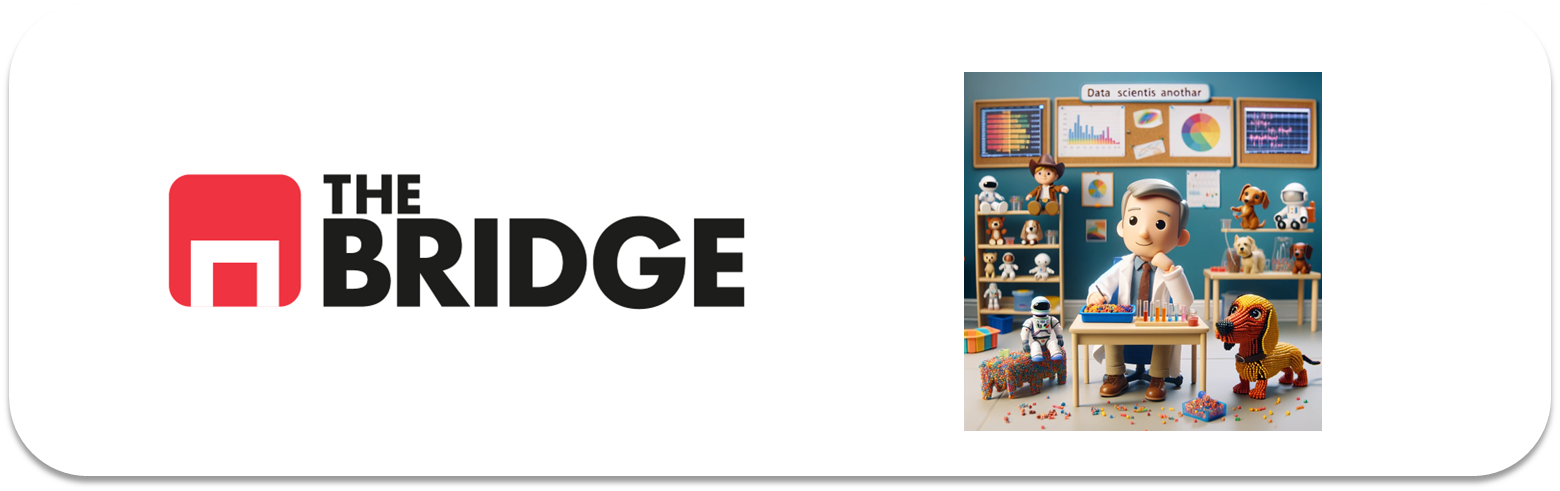

## Análisis de Datos: Forma y distribución de valores en variables numéricas

Nos quedamos en la sesión anterior en que era necesario poder "ver" cómo era esa dispersión de algunas de las variables importantes (y no tan directoras) de nuestro dataset. Para ello vamos a emplear los histogramas y (ahora en mucha menor medida) las funciones de densidad de probabilidad.

Pero antes ejecuta las siguientes celdas, en las que además de cargar los datos tienes una serie de funciones que te vendrán bien para hacer tus análisis [y que veremos como se construyen en el sprint siguiente cuando hablemos de visualización]:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from bootcampviztools import plot_multiple_boxplots  # funciones de visualización del curso

df_seguros = pd.read_csv("../data/Marketing-Customer-Analysis.csv")

In [2]:


def plot_histo_den(df, columns):
    num_cols = len(columns)
    num_rows = num_cols // 2 + num_cols % 2
    fig, axes = plt.subplots(num_rows, 2, figsize=(12, 6 * num_rows))
    axes = axes.flatten()

    for i, column in enumerate(columns):
        if df[column].dtype in ['int64', 'float64']:
            sns.histplot(df[column], kde=True, ax=axes[i])
            axes[i].set_title(f'Histograma y KDE de {column}')

    # Ocultar ejes vacíos
    for j in range(i + 1, num_rows * 2):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()




### Distribución de valores: Histogramas
Los histogramas son la mejor herramienta para ver la forma, dispersión y tendencia central de los datos. Nos dan la frecuencia de aparición de cada valor de los datos. Ya los hemos empleado y comentado, pero hagámoslo otra vez:



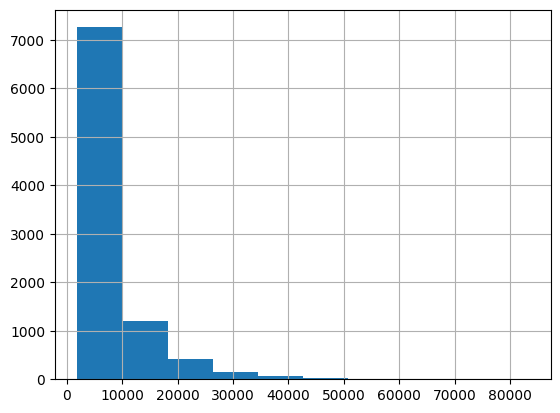

In [3]:
df_seguros["customer_lifetime_value"].hist();

Claramente existe una dispersión, pero fijate en otro dato que nos da el histograma, importante, **la distribución** de los valores, se concentran mucho en un rango inicial, y rápidamente decae la concentración y tenemos eso sí valores muy alejados que también se pierden por la escala (pero si recuerdas el boxplot de esta variable, recordaras que había muchos valores extremos):

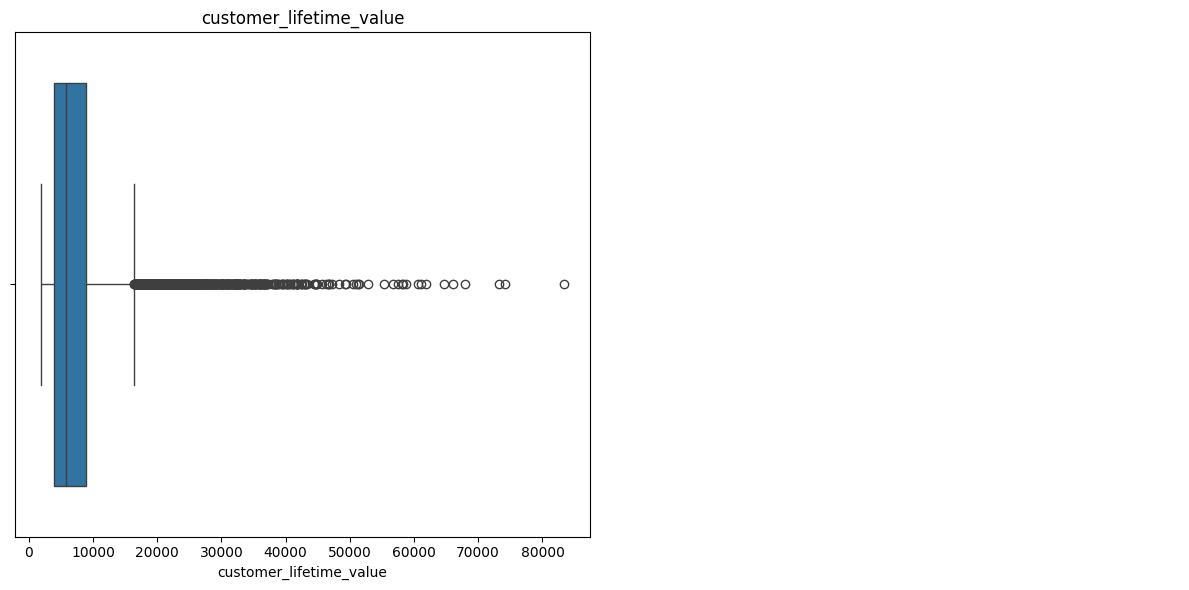

In [4]:
plot_multiple_boxplots(df_seguros, ["customer_lifetime_value"])

¿Y qué podemos hacer?
1. Analizar la variable filtrando los valores extremos.
2. En cualquier caso, parece interesante crearse una nueva variable categórica ordinal (agrupando los valores en intervalos con `pd.cut`, lo que se conoce como *binning*) y emplearla para hacer un análisis más detallado por CLV (recuerda que es nuestra variable directora). En el módulo de Machine Learning volveremos al *binning* como técnica de preprocesado.
[Y me sigo apuntando estas cosas para mi continuación de EDA]

Este mismo análisis lo haría para todas las variables, pintar su histograma y ver si merece la pena hacer análisis por cortes filtrando los valores extremos o no (aunque esto lo haré después de analizar dichos valores)



Aunque más por su aportación futura que actual, vamos a introducir en la parte gráfica del análisis la función densidad de probabilidad

### Distribución de valores: Función densidad de probabilidad
Nos sirve para ver la forma que tiene una variable, así como la probabilidad de aparición de cada uno de sus valores. Este tipo de gráficos se utiliza para variables contínuas. Las vamos presentando porque: 

* Hay determinadas "formas" de esa función que cuando los datos las siguen podemos aplicar ciertas propiedades a los mismos (en especial con la distribución normal, que veremos en el módulo de Inferencia)

* las emplearemos bastante más adelante ya que según la forma de esa función, podremos hacer transformaciones o tendremos que hacerlas para el modelado en sprints posteriores.

Vamos a mostrar la función de densidad (estimada) para `customer_lifetime_value` (junto con su histograma, con mayor resolución):

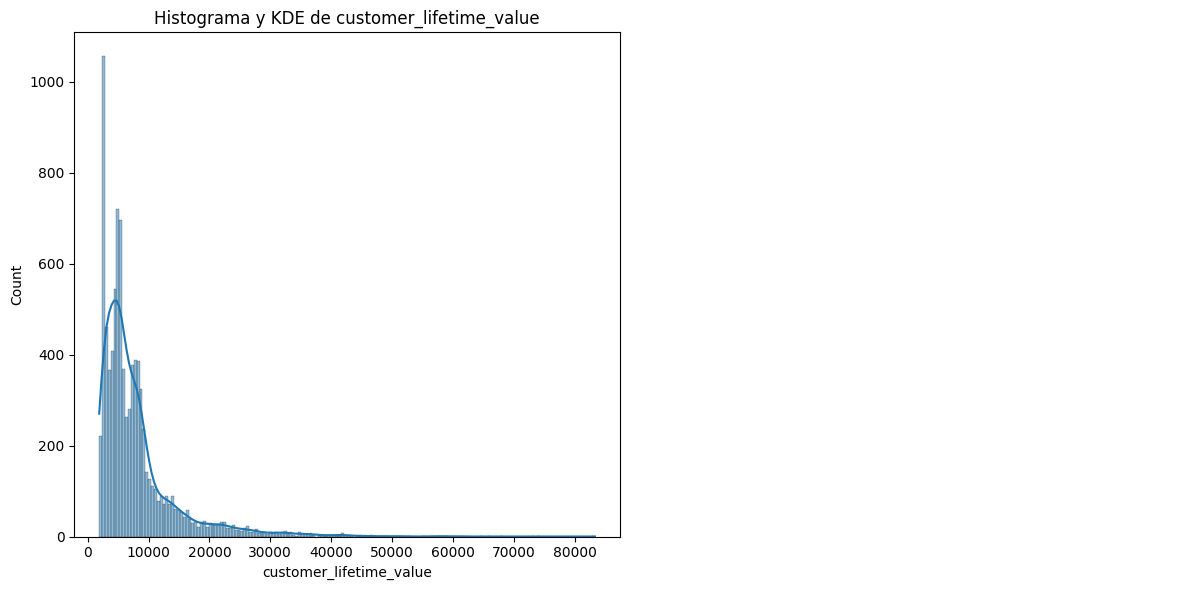

In [5]:
plot_histo_den(df_seguros,["customer_lifetime_value"])

Ahora con ese nivel no sólo queda más claro que existen posibles grupos sino que tenemos alguno especialmente significativo por la parte baja, no sólo todos esos valores en la "larga cola". 

Este gráfico además me sirve para combinar el análisis por histograma para saber a que tipo de función de densidad se podrían aproximar los datos de nuestra variable si fueran una serie estadística. Y de ahí aprovecharme de las propiedades de cada una (pero se escapa del ámbito del bootcamp). Lo que haríamos es comparar la forma a "ojo" (aunque existen mecanismos más rigurosos) y decidir si se parece a alguna de las siguientes (sobre todo a la normal, que es la que también se llama gaussiana o campana de gauss):

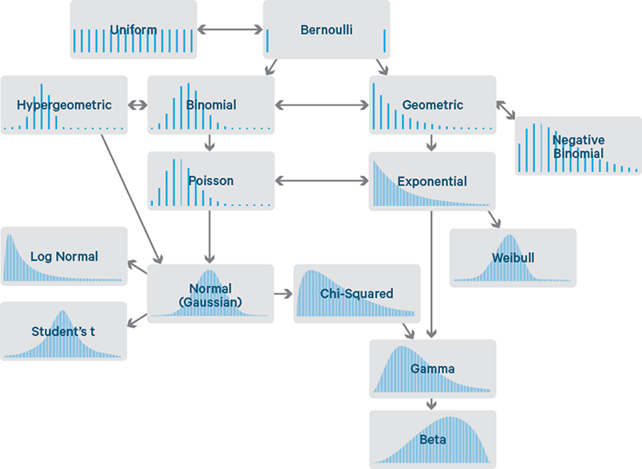

Para nosotros la aproximación de la distribución cobrará importancia más adelante, pero ya es bueno que nos la llevemos puesta en nuestros análisis. 

De hecho ahora vamos a aplicar el análisis de histograma-densidad a nuestro caso:

#### Seguros: Histogramas y densidades

Como hemos comentado este análisis nos servirá para decidir como tratar determinadas variables numéricas (segmentándolas o creando categorías) o incluso para mostrar alguna conclusión sobre ellas (por ejemplo sobre las variables directoras)

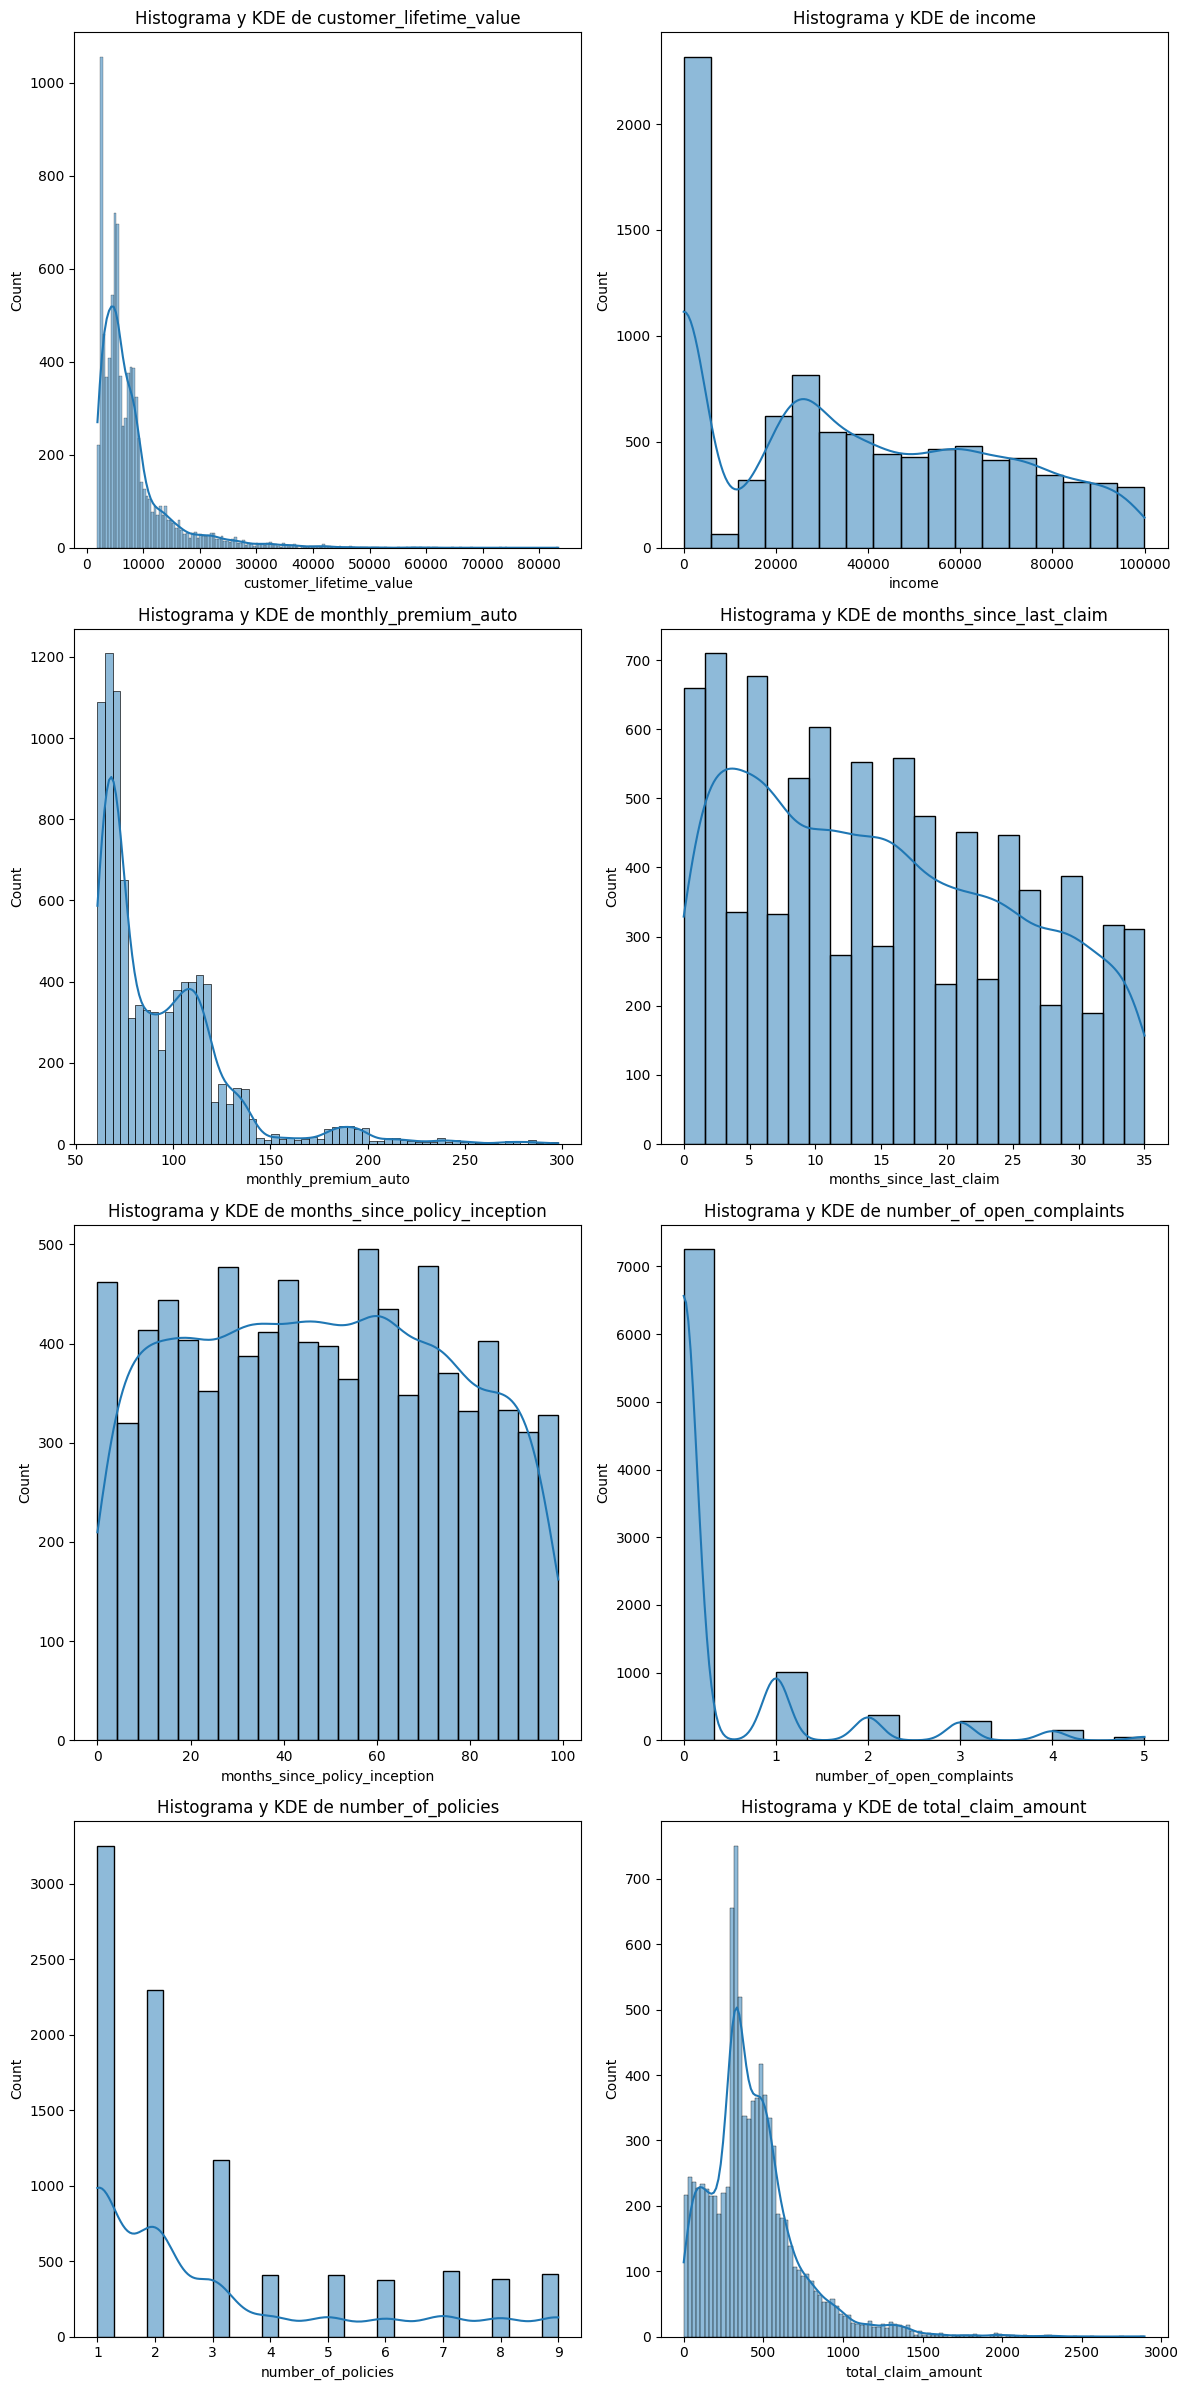

In [6]:
columnas_numericas = df_seguros.describe().columns.to_list()

plot_histo_den(df_seguros,columnas_numericas)

Una particularización que debemos tener en cuenta es que la función de distribución aplica a variables numéricas continuas, no debemos considerarlo en `number_of_policies` ni en `number_of_open_complaints`, ni las asociadas a meses.

Y ahora centrándonos en la variable directora (numérica), el customer_lifetime_value:
* Como ya habíamos visto tenemos que ver qué hacer con los valores extremos. En paralelo, yo vería que pinta tiene la distribución filtrando esos valores extremos. Y además ya miraría que valores son esos que tienen un claro pico en el histograma y lo tendría como un punto especial sobre el que llamar la atención o sobre el que informarme más (al igual que con el 14-86 de respuestas).  
* También haría una segmentación de clientes por nivel de income (donde hay una separación clara entre dos grandes grupos que analizaría por separado a la hora de compararlo con otras variables, en concreto con CLV y con respuestas) 
* Me apuntaría por si hay tiempo la posibilidad de abrir también un análisis por 3 grupos en función de la cantidad reclamada.
* Las curvas de CLV e Income tienen un cierto parecido que invita a estudiar su correlación (que por otro lado parece algo con cierto sentido, pero no necesariamente tiene que tenerlo)



### Medidas de forma: asimetría y curtosis

Hasta ahora hemos descrito la forma de las distribuciones "a ojo", con histogramas y densidades. Hay dos medidas que resumen esa forma en un número y que nos ayudan a comparar muchas variables de un vistazo.

#### Asimetría (*skewness*)

Indica si los valores se reparten igual a ambos lados de la media o si la distribución tiene una "cola" más larga hacia un lado:

* **Asimetría negativa** (< 0): la cola se alarga hacia los valores **bajos** (a la izquierda). La media queda por debajo de la mediana.
* **Simétrica** (≈ 0): mismo reparto a ambos lados; media, mediana y moda coinciden aproximadamente (como en la campana de Gauss).
* **Asimetría positiva** (> 0): la cola se alarga hacia los valores **altos** (a la derecha). La media queda por encima de la mediana.

<img src="./img/tipos_asimetria.png" width="600">

Se calcula con el coeficiente de asimetría de Fisher:

$$g_1 = \frac{\frac{1}{n}\sum\limits_{i=1}^n(x_i - \bar{x})^3}{s^3}$$

Como orientación: entre -0,5 y 0,5 la consideramos aproximadamente simétrica; por encima de 1 (o por debajo de -1), claramente asimétrica.

#### Curtosis (*kurtosis*)

Mide lo "apuntada" que es la distribución y, sobre todo, **lo pesadas que son sus colas** comparadas con una normal. `pandas` devuelve la curtosis *en exceso* (la de la normal vale 0):

* **> 0 (leptocúrtica)**: pico más alto y colas más pesadas que la normal → más valores extremos de lo "esperable".
* **≈ 0 (mesocúrtica)**: como la normal.
* **< 0 (platicúrtica)**: más achatada, colas ligeras → pocos valores extremos.

<img src="./img/curtosis.jpg" width="500">

#### Seguros: asimetría y curtosis

Las obtenemos para todas las numéricas a la vez y las ponemos junto a la media y la mediana:

In [7]:
columnas_numericas = df_seguros.describe().columns.to_list()

forma_seguros = pd.DataFrame({
    "asimetria": df_seguros[columnas_numericas].skew(),
    "curtosis": df_seguros[columnas_numericas].kurt(),
    "media": df_seguros[columnas_numericas].mean(),
    "mediana": df_seguros[columnas_numericas].median(),
}).round(2)

forma_seguros.sort_values("asimetria", ascending=False)

,asimetria,curtosis,media,mediana
customer_lifetime_value,3.03,13.82,8004.94,5780.18
number_of_open_complaints,2.78,7.75,0.38,0.00
monthly_premium_auto,2.12,6.19,93.22,83.00
total_claim_amount,1.71,5.98,434.09,383.95
number_of_policies,1.25,0.36,2.97,2.00
income,0.29,-1.09,37657.38,33889.50
months_since_last_claim,0.28,-1.07,15.10,14.00
months_since_policy_inception,0.04,-1.13,48.06,48.00


Fíjate en cómo encaja con todo lo anterior:

* `customer_lifetime_value` tiene la asimetría más alta (≈ 3) y una curtosis muy alta (≈ 14): larga cola a la derecha y muchos valores extremos. Por eso su media (≈ 8.000) está muy por encima de la mediana (≈ 5.800) y **la mediana la representa mejor**. Es la misma conclusión a la que llegamos con el histograma y el boxplot, pero ahora con un número.
* `monthly_premium_auto` y `total_claim_amount` también son claramente asimétricas a la derecha: candidatas a revisar sus valores extremos en el siguiente notebook.
* `income`, `months_since_last_claim` y `months_since_policy_inception` son casi simétricas y con curtosis negativa: valores bastante repartidos y sin colas pesadas.

Estas dos medidas son un **filtro rápido**: con decenas de variables, ordenar por asimetría te dice dónde mirar primero. Pero no sustituyen al histograma: dos distribuciones muy distintas pueden tener la misma asimetría.

[Y eso es todo casi hemos terminado, nos queda ver la parte de las anomalías y hacer un pequeño resumen de lo que hemos visto para rematar la unidad, venga nos vemos]